# Fresnel disk-pair intensity asymmetry

Companion to `create_paper_figs_kikuchi_short_range.ipynb`; same styling and conventions.

**Fixed relative to the previous version**

- **Box mirror off-by-one.** `infer_box2_from_box1` used `(H-hi, H-lo)`. The exact
  reflection of a half-open slice about the centre `H/2` is `(H+1-hi, H+1-lo)`. The pattern
  centre is `H/2` exactly here too — verified from the direct beam and from the mirror
  symmetry of both marginal profiles (PTO 212.0/209.0, BTO 216.0/214.0, boracite 303.0/303.0).
- **Axis units.** The asymmetry is now normalised, `(b1-b2)/(b1+b2) x 100`, so it really is a
  percentage and is comparable between materials. The old code plotted raw summed counts
  while labelling the axis "%".
- **Reciprocal calibration.** Per material, from the supercell extent, so the patterns carry
  a real scale bar and share one field of view.
- **Polarisation alignment** is now one flag with both operations, `y(t) -> -y(-t)`, instead
  of separate `sign_flip` / `tilt_flip`. See the note in the config cell.
- Dead commented-out cells (ROI selector, per-material duplicate figure) removed.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import PowerNorm

plt.style.use("paper")   # ~/.config/matplotlib/stylelib

sys.path.insert(0, "..")
from polarisation_direction import P_REVERSED
from kikuchi_com import mirror_box, BORACITE_EXTENT, DISK_LATTICE, disk_row_box, reflection, ROW_NAME          # exact half-open reflection about n/2

# Electron wavelength at 300 kV
_h, _m, _e, _c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
LAMBDA = _h / np.sqrt(2*_m*_e*300e3) / np.sqrt(1 + _e*300e3/(2*_m*_c**2)) * 1e10

FOV_INVA = 1.75    # half-width displayed, inverse angstrom, common to all three
SCALEBAR = 1.0     # inverse angstrom
TILT_SIGN = -1     # x-axis convention, applied to the tilt axis only

# Reflection order sets the colour, box width sets the line style.
# Colours come from the stylesheet cycle: navy, orange, green, purple, ...
CYCLE = plt.rcParams["axes.prop_cycle"].by_key()["color"]
ORDER_COLOUR = dict(zip(("100", "200", "300"), CYCLE))
# lighter tints of the same hues, readable on the dark pattern
LABEL_COLOUR = {"100": "#9ca2bb", "200": "#ecbc9c", "300": "#b2bfb0"}
WIDTH_STYLE  = {"1x1": (0, (1.5, 1.5)), "1x3": (0, (4, 1.8)), "1x5": "-"}
C_FULL = CYCLE[3]
FG, ZERO, GUIDE = "black", "black", "#9a9a96"   # text, zero lines, guide/legend grey

GAMMA, PMIN, PMAX = 0.3, 0.5, 99.8


In [2]:
# ── Per-material configuration ───────────────────────────────────────────────
# boxes: (order, width) -- box1 is built by kikuchi_com.disk_row_box on the detected disk
# lattice (DISK_LATTICE: spacing, half-width); the partner is its exact mirror.
#
# flip_polar: the BaTiO3 CIF is polarised opposite to the PbTiO3 one (nominal
# moments -38.2 vs +17.9 uC/cm2 against the ideal cubic reference). Mirroring a
# structure through the plane perpendicular to P is exact, so no re-simulation is
# needed, but it reverses the tilt sense as well as the measured asymmetry:
#     M R_y(theta) M = R_y(-theta)   =>   y_aligned(t) = -y(-t)
# Negating the value alone would also invert the odd (geometric) part of the
# curve. This is the old sign_flip + tilt_flip pair, as a single correct operation.
#
# NOTE ON BORACITE: in this low-angle disk regime its asymmetry has the opposite
# sign to PTO, so it is flipped here to make the columns comparable. In the
# Kikuchi figure it is NOT flipped, because at high angle it already matches PTO.
# The reason is that PTO itself reverses sign between the two regimes. Flipping
# to "match PTO" therefore is not a material property -- see the notes at the end.

# Disk data: the 4096-grid, full-detector Kikuchi short-range sims (41 tilts, +-0.6 deg). The
# dedicated disk sims (data/*_disks.npz) used a 1024 grid, which is not converged: boracite
# {100} 1x1 at zero tilt is -88.7 % at 1024 and -68.8 % at 4096 (these sims give -68.6 %).
MATERIALS = {
    "PTO": dict(
        formula=r"PbTiO$_3$", abbr="PTO", path="../data/short_range/PTO_short_range_21_sept_asymmetry_data.npz",
        cell=(3.9423, 3.8862), nrep=30, flip_polar=False,
        boxes=[("100", "1x1"),
               ("100", "1x3"),
               ("100", "1x5"),
               ("200", "1x1"),
               ("200", "1x3"),
               ("200", "1x5"),
               ("300", "1x1"),
               ("300", "1x3"),
               ("300", "1x5")]),
    "BTO": dict(
        formula=r"BaTiO$_3$", abbr="BTO", path="../data/short_range/BTO_kikuchi_final_15_slice_asymmetry_data.npz",
        cell=(4.0230, 3.9905), nrep=30, flip_polar=True,
        boxes=[("100", "1x1"),
               ("100", "1x3"),
               ("100", "1x5"),
               ("200", "1x1"),
               ("200", "1x3"),
               ("200", "1x5"),
               ("300", "1x1"),
               ("300", "1x3"),
               ("300", "1x5")]),
    "Boracite": dict(
        formula=r"Cu$_3$B$_7$ClO$_{13}$", abbr="boracite", path="../data/short_range/1_slice_thickness/boracite_kikuchi_1_slice_asymmetry_data.npz",
        cell=(17.1032, 17.1032), nrep=7,
        extent=(BORACITE_EXTENT, BORACITE_EXTENT),   # abTEM box, see kikuchi_com
        flip_polar=True,
        boxes=[("100", "1x1"),
               ("100", "1x3"),
               ("100", "1x5"),
               ("200", "1x1"),
               ("200", "1x3"),
               ("200", "1x5")]),
}

for cfg in MATERIALS.values():
    a0, a1 = cfg["cell"]; n = cfg["nrep"]
    e0, e1 = cfg.get("extent", (n*a0, n*a1))       # simulation box (A)
    cfg["kpp"] = (1.0 / e0, 1.0 / e1)               # inverse angstrom per pixel

for k, cfg in MATERIALS.items():
    print(f"{k:9s} A^-1/px = {cfg['kpp'][0]:.6f} / {cfg['kpp'][1]:.6f}   "
          f"{len(cfg['boxes'])} boxes")


PTO       A^-1/px = 0.008455 / 0.008577   9 boxes
BTO       A^-1/px = 0.008286 / 0.008353   9 boxes
Boracite  A^-1/px = 0.005906 / 0.005906   6 boxes


In [3]:
def asym(patterns, box1, box2):
    """Normalised intensity asymmetry, per cent: (b1 - b2) / (b1 + b2)."""
    (y1, y2), (x1, x2) = box1
    (Y1, Y2), (X1, X2) = box2
    b1 = patterns[:, y1:y2, x1:x2].sum(axis=(1, 2))
    b2 = patterns[:, Y1:Y2, X1:X2].sum(axis=(1, 2))
    return (b1 - b2) / (b1 + b2) * 100


def mirror_yx(box, H):
    """Exact mirror of a ((y_lo,y_hi),(x_lo,x_hi)) box through the centre H/2."""
    (lo, hi), (x0, x1) = box
    a, b, _, _ = mirror_box((lo, hi, x0, x1), H)
    return ((a, b), (x0, x1))


def process(name, cfg):
    d = np.load(cfg["path"])
    p = d["diffraction_images"].astype(np.float64)
    if p.ndim == 4:
        p = p[:, 0]
    n_tilt, H, W = p.shape
    t = np.asarray(d["tilt_y_values"], dtype=float)

    curves = {}
    for order, width in cfg["boxes"]:
        box1 = disk_row_box((H, W), *DISK_LATTICE[name], int(order[0]), int(width[-1]))
        box2 = mirror_yx(box1, H)
        curves[(order, width)] = dict(vals=asym(p, box1, box2), box1=box1, box2=box2)

    # naive whole-pattern comparison: equal, properly paired halves. Row 0 is the
    # unpaired Nyquist row and row H/2 is the centre, so both are excluded.
    lo = p[:, 1:H//2, :].sum(axis=(1, 2))
    hi = p[:, H//2+1:, :].sum(axis=(1, 2))
    full = (lo - hi) / (lo + hi) * 100

    return dict(tilt=t, curves=curves, full=full,
                zero=p[int(np.argmin(abs(t)))], H=H, W=W)


results = {k: process(k, cfg) for k, cfg in MATERIALS.items()}
for k, r in results.items():
    rng = np.concatenate([c["vals"] for c in r["curves"].values()])
    print(f"{k:9s} {r['H']}x{r['W']}  n={len(r['tilt'])}  "
          f"box asym {rng.min():+7.3f}..{rng.max():+7.3f} %   full {r['full'].min():+7.3f}..{r['full'].max():+7.3f} %")


PTO       4096x4096  n=41  box asym -98.514..+97.936 %   full -48.910..+39.785 %
BTO       4096x4096  n=41  box asym -97.493..+99.290 %   full -53.877..+58.362 %
Boracite  4096x4096  n=41  box asym -97.179..+98.995 %   full -55.533..+54.471 %


### Box placement check
Axes on, gridded every 20 px, so coordinates can be read off and pasted back into the config.
Run after editing `MATERIALS`; nothing below depends on it.

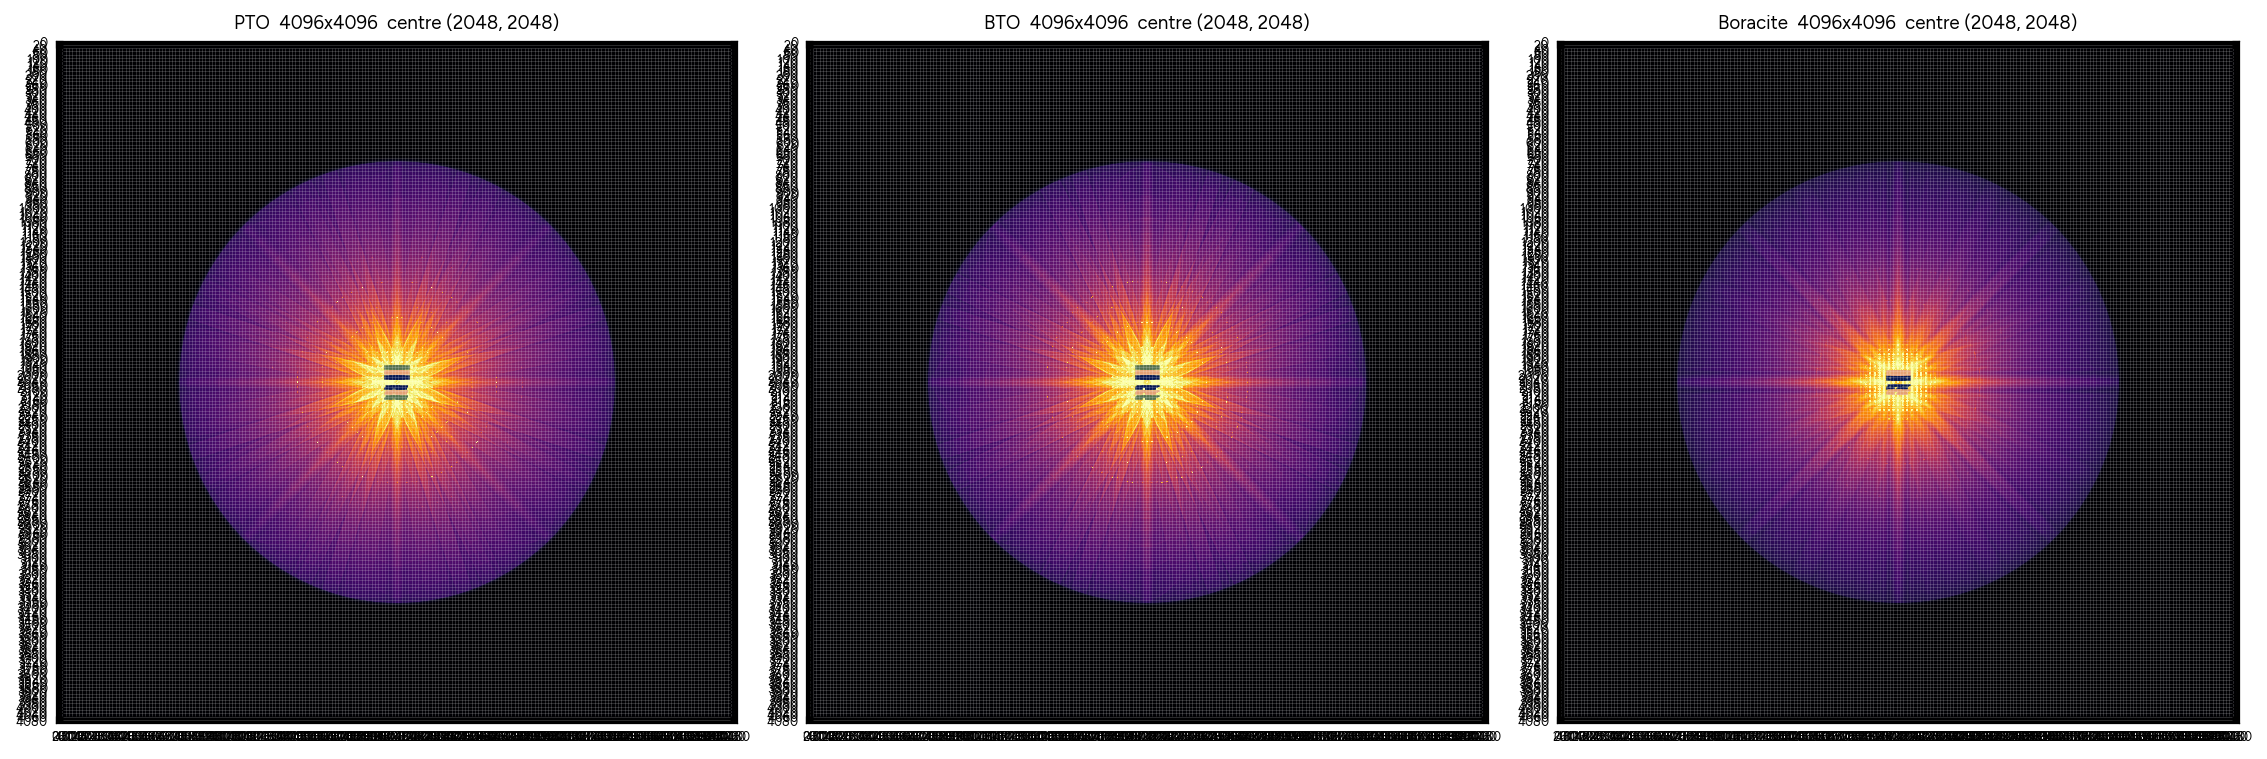

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, (name, res) in zip(axes, results.items()):
    img = res["zero"]
    vmin, vmax = np.percentile(img, [PMIN, PMAX])
    ax.imshow(img, cmap="inferno", origin="upper",
              norm=PowerNorm(gamma=GAMMA, vmin=vmin, vmax=vmax))
    for (order, width), c in res["curves"].items():
        col = ORDER_COLOUR[order]
        for b, ls in ((c["box1"], "-"), (c["box2"], "--")):
            (lo, hi), (x0, x1) = b
            ax.add_patch(Rectangle((x0, lo), x1-x0, hi-lo, lw=1.2,
                                   edgecolor=col, facecolor="none", linestyle=ls))
    ax.set_xticks(range(0, res["W"]+1, 20)); ax.set_yticks(range(0, res["H"]+1, 20))
    ax.tick_params(labelsize=6); ax.grid(True, color="white", alpha=0.2, lw=0.4)
    ax.set_title(f"{name}  {res['H']}x{res['W']}  centre ({res['H']//2}, {res['W']//2})", fontsize=9)
plt.show()


saved figures/disks_intensity.{pdf,png}


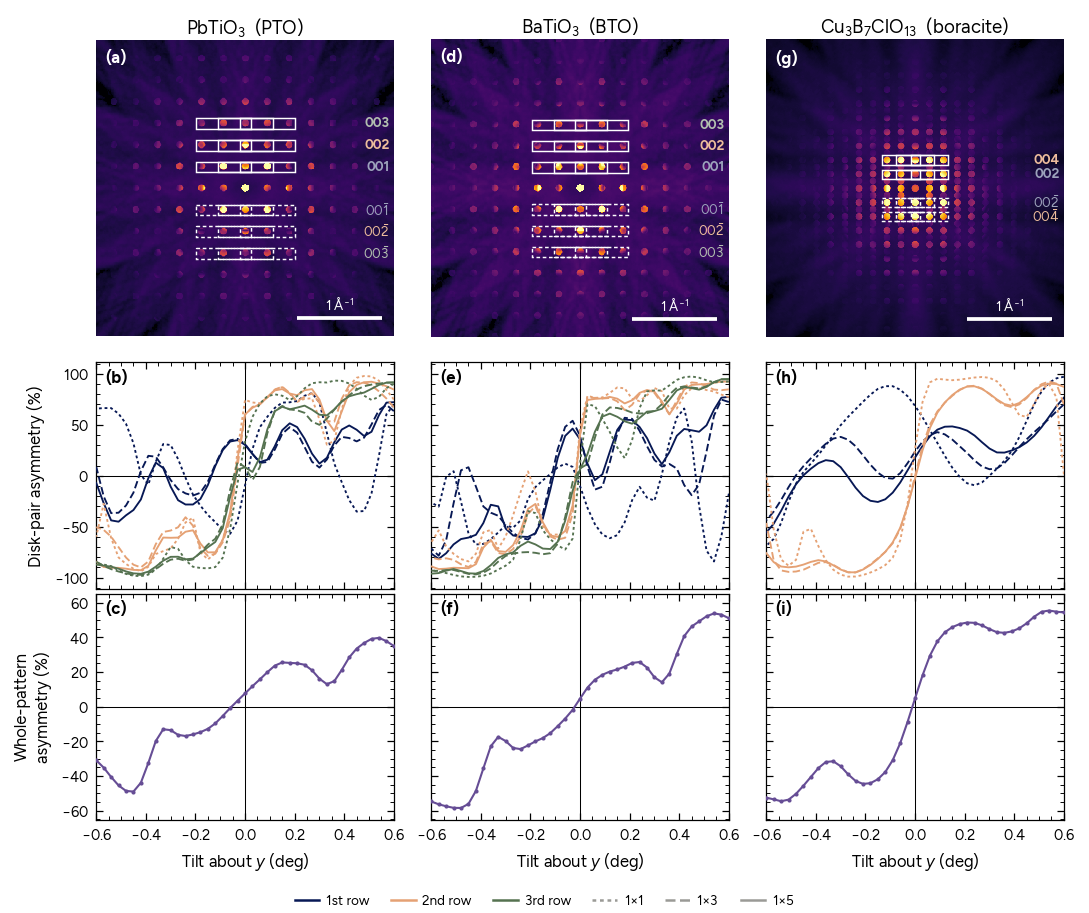

In [5]:
# reduced main-text set: the same three ROIs for every material
LESS = [("100", "1x1"), ("100", "1x3"), ("200", "1x3")]


def disks_figure(raw=False, aligned=False, final=False, best=False):
    """raw=True: no polar alignment, tilt as simulated, 'unflipped_' prefix.
    aligned=True: every material mirrored to PTO's polarisation (P_REVERSED), 'aligned_' prefix.
    final=True: common polarisation frame with P towards the TOP box, i.e. PTO mirrored and
    BTO/boracite as simulated (both are built reversed relative to PTO); 'corrected_final/' prefix.
    best=True: only the LESS ROIs, 'less_' added to the file name."""
    pre = "unflipped_" if raw else "aligned_" if aligned else "corrected_final/corrected_final_" if final else ""
    pre += "less_" if best else ""
    # ── Publication figure: 180 mm double column, styled by the paper stylesheet (cell 1) ─
    MM = 1 / 25.4

    fig, axes = plt.subplots(3, 3, figsize=(180*MM, 150*MM),
                             gridspec_kw={"height_ratios": [1.5, 1.0, 1.0]},
                             layout="constrained")
    fig.get_layout_engine().set(h_pad=0.01, w_pad=0.01, hspace=0.015, wspace=0.03)

    letters = iter("abcdefghi")
    box_all  = np.concatenate([c["vals"] for r in results.values() for c in r["curves"].values()])
    full_all = np.concatenate([r["full"] for r in results.values()])
    box_lim, full_lim = np.abs(box_all).max()*1.12, np.abs(full_all).max()*1.12


    def panel_label(ax, txt, colour=FG):
        ax.text(0.03, 0.965, f"({txt})", transform=ax.transAxes, va="top", ha="left",
                fontsize=8, fontweight="bold", color=colour)


    for col, (name, cfg) in enumerate(MATERIALS.items()):
        res = results[name]
        curves = {k: v for k, v in res["curves"].items() if not best or k in LESS}
        kpp0, kpp1 = cfg["kpp"]
        H, W = res["H"], res["W"]
        t_plot = (1 if raw else TILT_SIGN) * res["tilt"]
        flip = (lambda v: -v[::-1]) if (P_REVERSED[name] if aligned else (not P_REVERSED[name]) if final else cfg["flip_polar"]) and not raw else (lambda v: v)

        # ══ Row 0: zero-tilt pattern, common field of view in inverse angstrom ═══
        ax = axes[0, col]
        h0, h1 = int(FOV_INVA / kpp0), int(FOV_INVA / kpp1)
        img = res["zero"][H//2-h0:H//2+h0, W//2-h1:W//2+h1]
        vmin, vmax = np.percentile(img, [PMIN, PMAX])
        kx, ky = h1*kpp1, h0*kpp0
        ax.imshow(img, cmap="inferno", origin="upper", extent=[-kx, kx, ky, -ky],
                  aspect="equal", norm=PowerNorm(gamma=GAMMA, vmin=vmin, vmax=vmax), rasterized=True)

        seen = set()
        for (order, width), c in curves.items():
            for b, ls in ((c["box1"], "-"), (c["box2"], (0, (2.5, 1.8)))):
                (lo, hi), (x0, x1) = b
                ax.add_patch(Rectangle(((x0-W//2)*kpp1, (lo-H//2)*kpp0),
                                       (x1-x0)*kpp1, (hi-lo)*kpp0,
                                       lw=0.7, edgecolor="white", facecolor="none", linestyle=ls))
            if order not in seen:                      # label each reflection and its Friedel partner once
                seen.add(order)
                for b, mir in ((c["box1"], False), (c["box2"], True)):
                    (lo, hi), _ = b
                    ax.text(kx*0.97, ((lo + hi)/2 - H//2)*kpp0, reflection(name, order[0], mir),
                            color=LABEL_COLOUR[order], ha="right", va="center",
                            fontsize=6.5, fontweight="bold")
        if final:                                   # P points to the top (solid) box
            ax.annotate("", xy=(-kx*0.80, -ky*0.72), xytext=(-kx*0.80, -ky*0.44),
                        arrowprops=dict(arrowstyle="-|>", color="white", lw=1.0))
            ax.text(-kx*0.74, -ky*0.58, "P", color="white", va="center", fontsize=7, fontweight="bold")

        x_hi, y_lo = kx*0.92, ky*0.88
        ax.plot([x_hi-SCALEBAR, x_hi], [y_lo, y_lo], color="white", lw=1.8,
                solid_capstyle="butt", zorder=5)
        ax.text(x_hi-SCALEBAR/2, y_lo-ky*0.035, rf"{SCALEBAR:.0f} $\mathrm{{\AA}}^{{-1}}$",
                color="white", ha="center", va="bottom", fontsize=6.5, zorder=5)

        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        panel_label(ax, next(letters), colour="white")
        ax.set_title(rf"{cfg['formula']}  ({cfg['abbr']})", pad=3, fontsize=9)

        # ══ Row 1: disk-pair asymmetry ═══════════════════════════════════════════
        ax = axes[1, col]
        ax.axhline(0, color=ZERO, lw=0.5, zorder=0)
        ax.axvline(0, color=ZERO, lw=0.5, zorder=0)
        for (order, width), c in curves.items():
            ax.plot(t_plot, flip(c["vals"]), color=ORDER_COLOUR[order],
                    linestyle=WIDTH_STYLE[width], lw=0.9, zorder=3)
        ax.set_ylim(-box_lim, box_lim); ax.set_xlim(t_plot.min(), t_plot.max())
        if col == 0:
            ax.set_ylabel("Disk-pair asymmetry (%)")
        else:
            ax.set_yticklabels([])
        ax.set_xticklabels([])
        panel_label(ax, next(letters))

        # ══ Row 2: naive whole-pattern comparison ════════════════════════════════
        ax = axes[2, col]
        ax.axhline(0, color=ZERO, lw=0.5, zorder=0)
        ax.axvline(0, color=ZERO, lw=0.5, zorder=0)
        ax.plot(t_plot, flip(res["full"]), "-o", ms=2.0, color=C_FULL,
                markeredgewidth=0, zorder=3)
        ax.set_ylim(-full_lim, full_lim); ax.set_xlim(t_plot.min(), t_plot.max())
        ax.set_xlabel(r"Tilt about $y$ (deg)")
        if col == 0:
            ax.set_ylabel("Whole-pattern\nasymmetry (%)")
        else:
            ax.set_yticklabels([])
        panel_label(ax, next(letters))

    # one figure-level legend under the whole grid, so it cannot collide with data:
    # colour = reflection order, line style = box width
    from matplotlib.lines import Line2D
    orders = sorted({o for o, _ in LESS}) if best else ["100", "200", "300"]
    widths = sorted({w for _, w in LESS}) if best else ["1x1", "1x3", "1x5"]
    handles = ([Line2D([], [], color=ORDER_COLOUR[o], lw=1.2) for o in orders]
               + [Line2D([], [], color=GUIDE, lw=1.2, ls=WIDTH_STYLE[w]) for w in widths])
    labels = [ROW_NAME[int(o[0])] for o in orders] + [w.replace("x", r"$\times$") for w in widths]
    fig.legend(handles, labels, ncol=len(handles), loc="outside lower center",
               handlelength=1.8, columnspacing=1.6, borderaxespad=0.1)

    fig.savefig(f"figures/{pre}disks_intensity.pdf")
    fig.savefig(f"figures/{pre}disks_intensity.png")
    print(f"saved figures/{pre}disks_intensity.{{pdf,png}}")
    plt.show()


disks_figure()

### Unflipped version
Raw values as simulated: no `flip_polar` alignment, and `TILT_SIGN` = +1 (tilt axis not mirrored). Saved with the `unflipped_` prefix.

saved figures/unflipped_disks_intensity.{pdf,png}


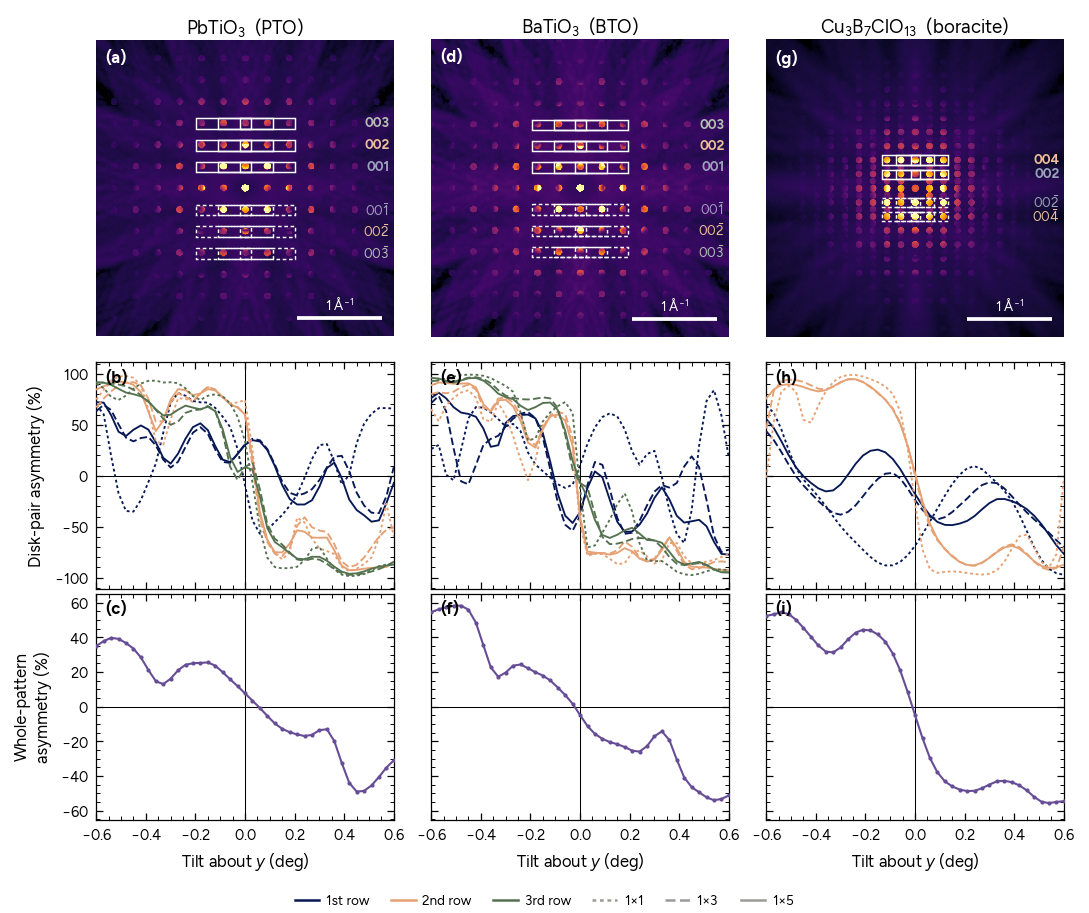

In [6]:
disks_figure(raw=True)

### Correctly oriented version
What the sims would give had every structure been polarised the same way along the measured
axis (as PTO, +x). From `polarisation_direction.py`: BTO and boracite were simulated with P
reversed relative to PTO (lab P_x = +38.2, -17.9, -0.71 uC/cm2), so both are mirrored,
y(t) -> -y(-t); PTO is unchanged. Tilt axis uses the same `TILT_SIGN` convention as the main
figure. Identical to the main disks figure, which already flips both. Saved with the `aligned_` prefix.

saved figures/aligned_disks_intensity.{pdf,png}


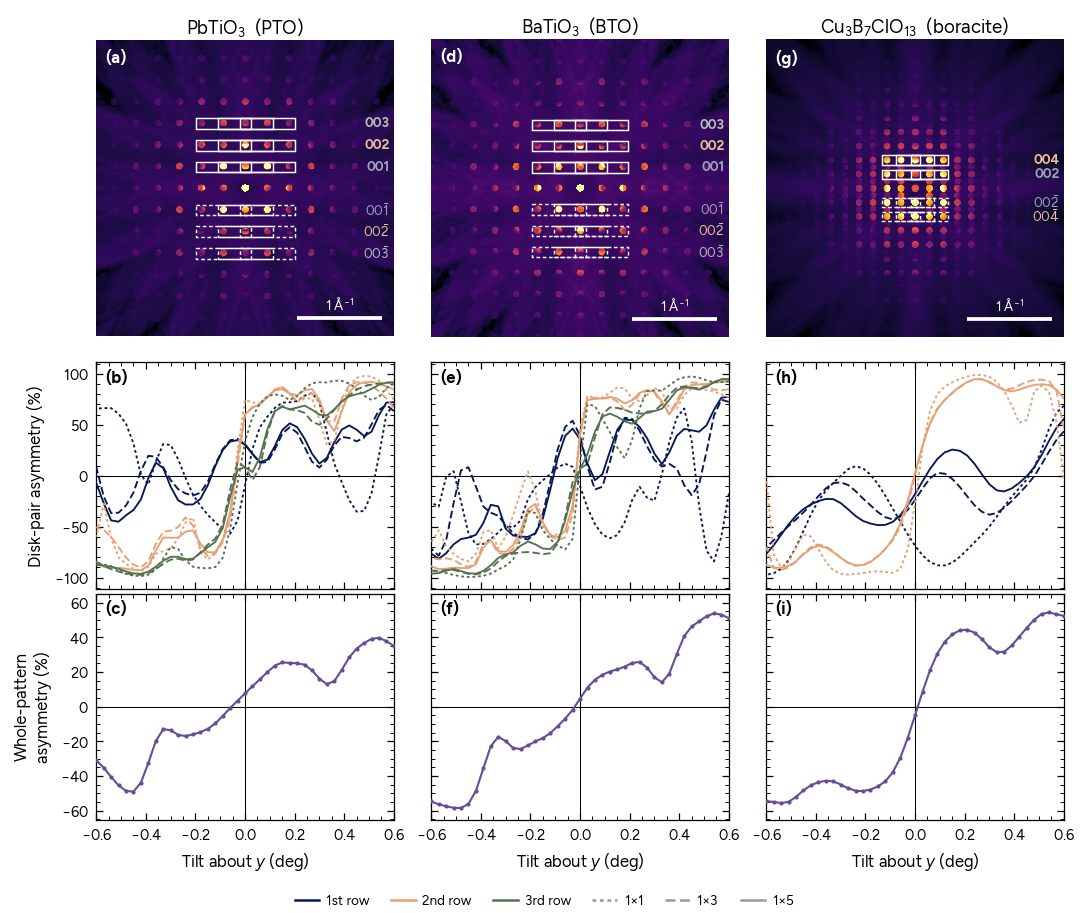

In [7]:
disks_figure(aligned=True)

## Notes

**Zero-tilt asymmetry per reflection.** Printed below for the caption.

**On the boracite flip.** Aligning a material's curve to PTO's is not a material property,
because *PTO itself reverses sign between the low-angle and high-angle regimes* (see the
Kikuchi notebook: PTO is -10 to -28 % below 16 mrad and +2 % beyond 33 mrad, while its
non-polar control axis stays flat at <0.15 %). Boracite does not reverse. So "flip to match
PTO" gives boracite one answer here and the opposite answer in the Kikuchi figure.

The defensible convention is to align by the **CIF polarisation direction**, which is a
property of the input structure. That is known for the two perovskites (PTO -38.2, BTO
+17.9 uC/cm2 nominal, so BTO flips) but has not been established for boracite's Pca2_1
structure, which has no simple paraelectric reference to measure against. Until it is, state
the convention explicitly in the caption rather than presenting the relative signs as a
result.

In [8]:
print(f"{'material':9s} {'reflection':11s} {'box':6s} {'asym at 0 tilt (%)':>20s}")
for name, cfg in MATERIALS.items():
    res = results[name]
    i0 = int(np.argmin(abs(res["tilt"])))
    s = -1 if cfg["flip_polar"] else 1
    for (order, width), c in res["curves"].items():
        print(f"{name:9s} {'{'+order+'}':11s} {width:6s} {s*c['vals'][i0]:>+20.4f}")
    print(f"{name:9s} {'whole pattern':18s} {s*res['full'][i0]:>+20.4f}")


material  reflection  box      asym at 0 tilt (%)
PTO       {100}       1x1                 -9.4357
PTO       {100}       1x3                +31.1790
PTO       {100}       1x5                +30.3294
PTO       {200}       1x1                +74.4818
PTO       {200}       1x3                +60.1462
PTO       {200}       1x5                +60.2594
PTO       {300}       1x1                +33.5570
PTO       {300}       1x3                 +8.4673
PTO       {300}       1x5                 +8.3912
PTO       whole pattern                   +7.7254
BTO       {100}       1x1                -10.2410
BTO       {100}       1x3                +39.2703
BTO       {100}       1x5                +35.7530
BTO       {200}       1x1                +47.1078
BTO       {200}       1x3                +41.2099
BTO       {200}       1x5                +40.1717
BTO       {300}       1x1                +12.4178
BTO       {300}       1x3                 +7.2023
BTO       {300}       1x5                 +6.3585


saved figures/corrected_final/corrected_final_disks_intensity.{pdf,png}


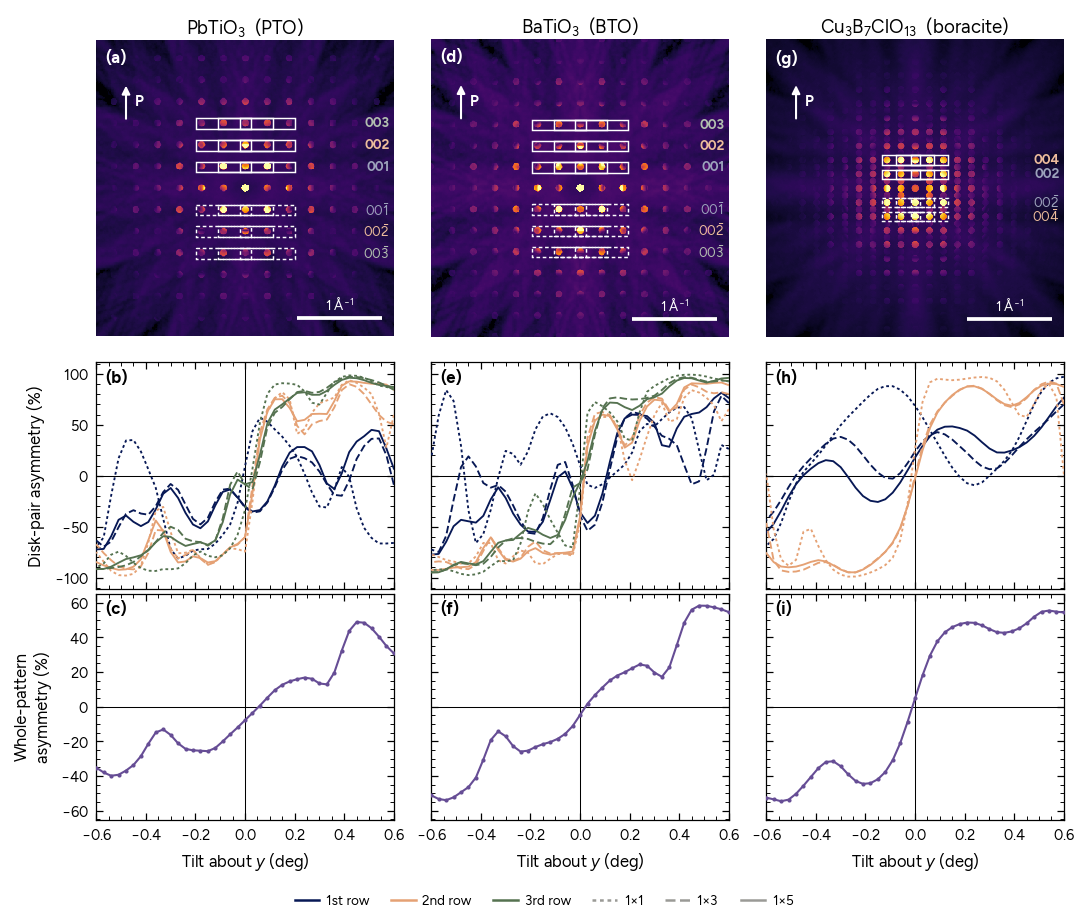

In [9]:
disks_figure(final=True)

saved figures/corrected_final/corrected_final_less_disks_intensity.{pdf,png}


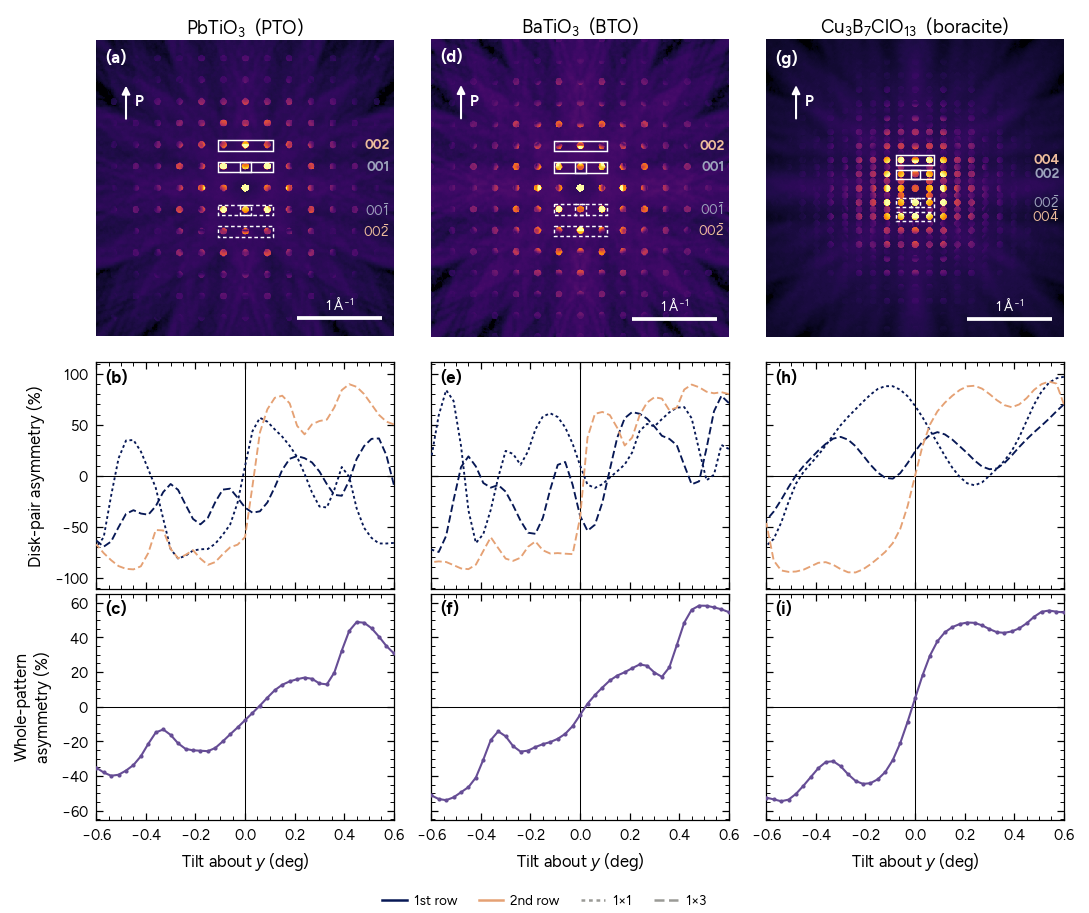

In [10]:
disks_figure(final=True, best=True)